# What each fitted model predicts, for one neuron → `figure_tuning.pdf`

One column per model, for the neuron `tuning_plots.ipynb` draws the data of. Top row: the
90°-apart chord family as a ring, coloured by predicted rate. Bottom row: predicted rate
against the objects' midpoint angle, one curve per inter-object angle.

Everything here is a **prediction** — the models' parameters come from the cache, and the
same conditions are evaluated for each. Two choices make this figure comparable to the data
figure beside it: the rings are rotated by that unit's `orientation_deg`, exactly as
`tuning_plots.ipynb` rotates its own, and the line row is drawn on **that figure's y axis**,
read out of its `LINE_YLIM` / `LINE_YTICKS` — so a difference in height between the two
figures means what it looks like it means.

In [1]:
import matplotlib.pyplot as plt

import common
common.set_style()
import contrast_lib
import data_lib as dl
import fit_lib
import figure_tuning_lib as ftl
import models_lib
import ring_lib

OUTPUT = 'figure_tuning.pdf'
UNIT = ('Perle', '2022-06-11', 143, -88)   # subject, session, unit, ring rotation (deg)

# The models this figure draws, left to right, and what to call the last one.
MODELS = (
    'weighted_average',
    'normalization',
    'inhibition',
    # 'softmax',
    # 'priority_map',
    'basis_function',
    'future_field',
)
COLUMN_LABELS = {}

RING_SEP_DEG = 90.0                      # inter-object angle of the ring row
SEPS_DEG = (90., 120., 150., 180.)       # one line-row curve per angle
RING_N_DENSE = 18                        # chords per ring, as in tuning_plots.ipynb
N_DENSE = 36                             # line-row samples per curve, likewise
N_DENSE_1OBJ = 180

DATA_NOTEBOOK = 'tuning_plots.ipynb'     # where the line row's y axis comes from

# Which pair of objects the contrast-weighted column is drawn for. That model's rate depends
# on the two identities as well as their angles, so it has no single tuning curve; the other
# models ignore this. `('c', 'b')` is the highest-contrast pair the task shows (d = +0.331),
# i.e. the condition where the weighting is most visible. `('a', 'b')` (d = +0.012) would draw
# it almost exactly as the plain retinotopic sum.
CONTRAST_PAIR = ('c', 'b')

In [2]:
subject, session, unit_id, orientation_deg = UNIT
fits = ring_lib.unit_fits(subject, session, unit_id, fit_lib.FitConfig())
models = models_lib.build_models(MODELS)

# The data figure pins this unit's line-row axis; read the pin rather than copying the
# numbers, so the two figures cannot end up on different scales.
ylim = dl.notebook_literal(DATA_NOTEBOOK, 'LINE_YLIM')[unit_id]
yticks = dl.notebook_literal(DATA_NOTEBOOK, 'LINE_YTICKS')[unit_id]
print(f'line row on {DATA_NOTEBOOK}\'s axis for unit {unit_id}: {ylim}, ticks {yticks}')

DCTR = contrast_lib.relative_contrast(*CONTRAST_PAIR)
print(f'contrast-weighted column drawn for the pair {CONTRAST_PAIR}: d = {DCTR:+.3f}')

  Perle/2022-06-11 unit 143: from cache
line row on tuning_plots.ipynb's axis for unit 143: (5, 14), ticks (5, 10)
contrast-weighted column drawn for the pair ('c', 'b'): d = +0.331


  Future Field: 1-object prediction is flat, so there is no peak to centre on; using the fitted theta (359.6 deg)
saved figure_tuning.pdf


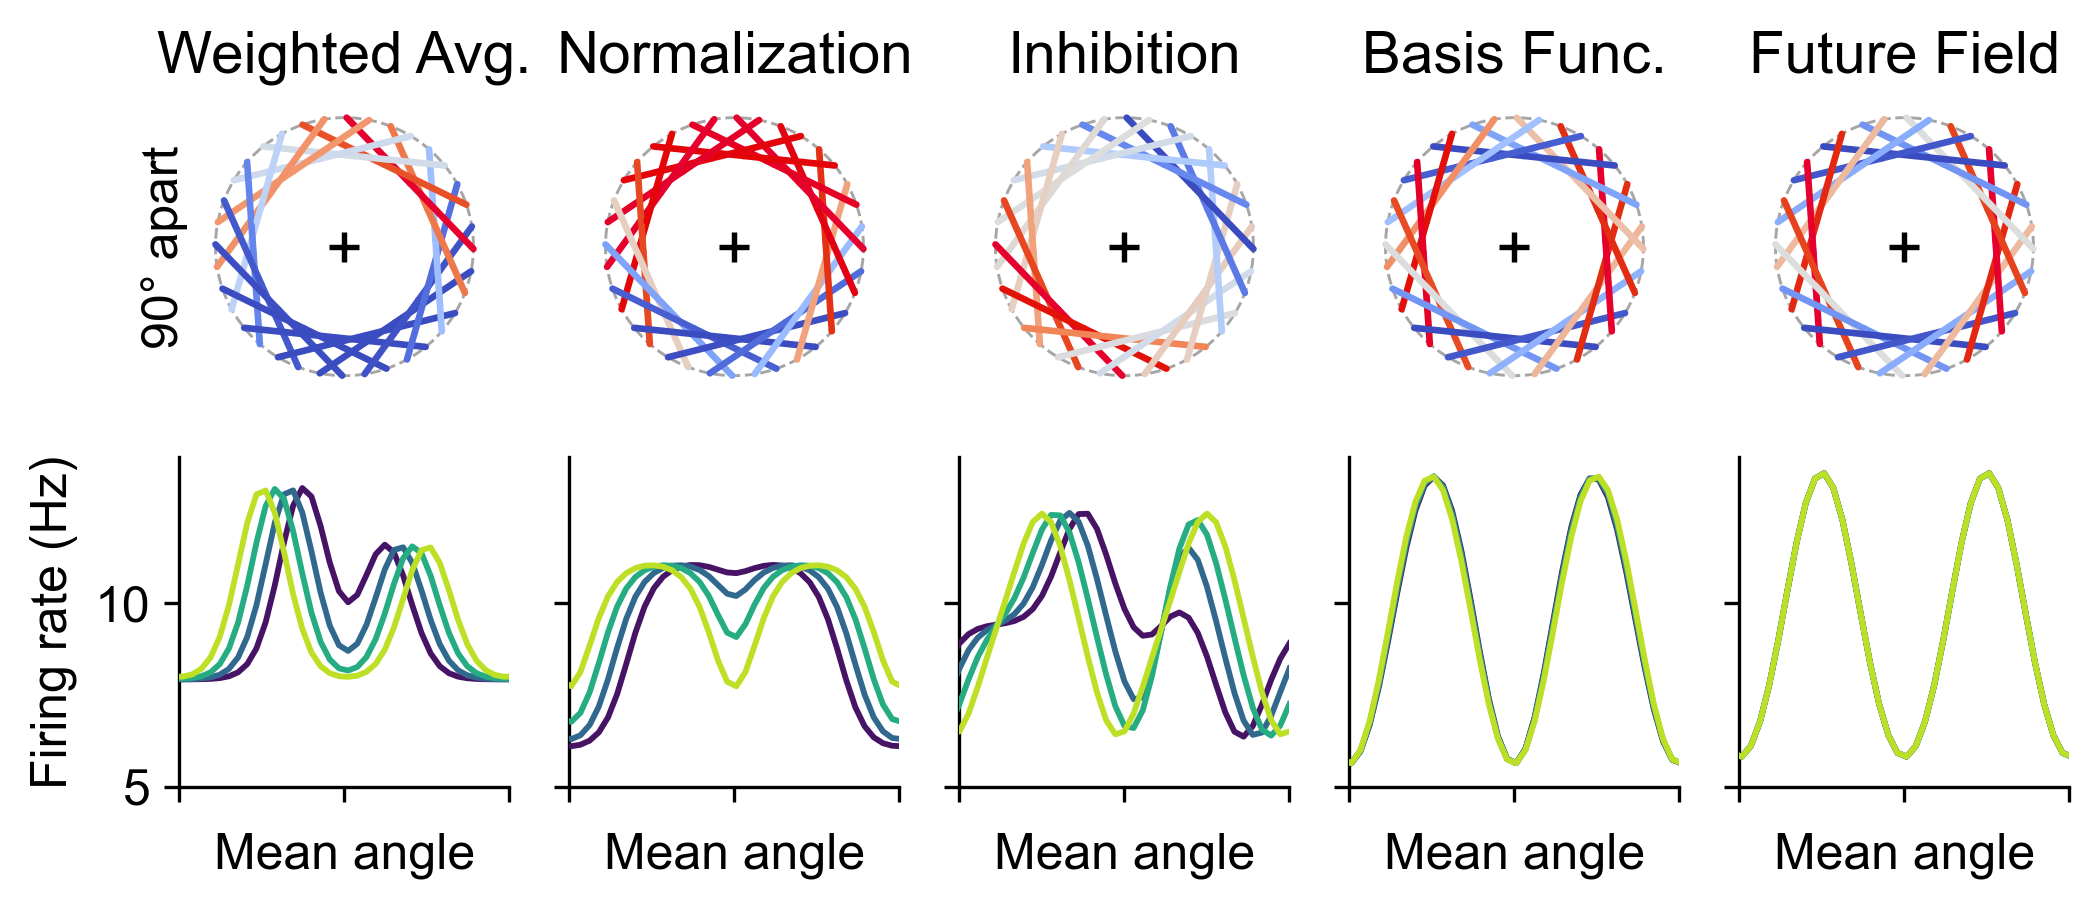

In [3]:
panels = ftl.build_panels(
    models, fits, MODELS, seps_deg=SEPS_DEG, ring_sep_deg=RING_SEP_DEG, n_dense=N_DENSE,
    ring_n_dense=RING_N_DENSE, n_dense_1obj=N_DENSE_1OBJ, orientation_deg=orientation_deg,
    labels=COLUMN_LABELS, dctr=DCTR)

fig, _ = ftl.model_tuning_grid(
    panels, ring_sep_deg=RING_SEP_DEG, rotate_deg=orientation_deg, dpi=300,
    share='panel',                    # each ring on its own colour scale, as the data figure
    cmap=ring_lib.boosted_cmap(value=0.9, saturation=1.0, blend=0.5),
    colors=ftl.sep_colors(SEPS_DEG, cmap='viridis'),
    line_ylim=ylim, line_yticks=yticks, show_xticklabels=False,
    center='peak', one_obj=False, line_share_y=True,
    # ── spacing, all in inches ──────────────────────────────────────────────
    # `ring_size_in` sets the figure's scale and everything else is measured against it;
    # `figsize` / `wspace` / `hspace` / `ring_frac` do nothing while it is set. Column pitch
    # is panel_width_in + col_gap_in, and the figure sizes itself to hold what these ask for.
    ring_size_in=1.0,        # ring diameter (the ring axes are square at this size)
    panel_width_in=1.1,     # column width. At 1.0 the column is exactly its ring, which is
                             # what it used to be, and the column titles then collide.
    col_gap_in=0.2,         # gap between columns
    line_height_in=1.1,      # height of the line row
    row_gap_in=0.2,          # gap between ring rows (only bites with several ring rows)
    line_gap_in=0.2,         # gap between the bottom ring row and the line row
    margins_in=(0.70, 0.08, 0.32, 0.60),   # left, right, top, bottom
    # ────────────────────────────────────────────────────────────────────────
    range_labels=False, colorbar=False, legend=False)

common.save(fig, OUTPUT)
plt.show()